### Procesamiento de Lenguaje Natural I
# **Desafío 2**

#### **Alumno 1:** Lerner, Federico Ezequiel - a2619

#### **Alumno 2:** Makk, Azul de los Angeles - a2622

## Custom embeddings con Gensim: *Guerra y paz* (León Tolstói)

**Objetivo:** entrenar embeddings de palabras propios con Gensim sobre un corpus elegido por nosotros, evaluarlos (cualitativa y cuantitativamente), analizar las similitudes que aprenden y visualizar los vectores en 2 dimensiones para buscar agrupaciones de palabras.

**¿Por qué este corpus?** Probamos primero con el dataset de canciones de clase (por ejemplo, la poesía de Emily Dickinson), pero cada artista tiene a lo sumo ~30 mil palabras. Con tan poco texto la mayoría de las palabras aparece pocas veces y los vecinos más cercanos resultan muy ruidosos. *Guerra y paz* (traducción al inglés de Project Gutenberg) tiene ~560 mil palabras: unas 20 veces más. Además mezcla campos semánticos bien distintos (batallas y ejército, familia y aristocracia, emociones, geografía de Rusia y Europa), lo que hace más interesante buscar grupos en el espacio de embeddings.

**Contenido**
1. Datos
2. Preprocesamiento (incluye detección de nombres compuestos con `Phrases`)
3. Experimentos con hiperparámetros: evaluación cualitativa y **cuantitativa** (WordSim-353, SimLex-999, analogías) y comparación con **FastText**
4. Términos más y menos similares, y analogías
5. Visualización 2D con t-SNE, **validación** de la proyección y de los grupos, y gráfico interactivo
6. Conclusiones

In [1]:
%pip install -q gensim scikit-learn matplotlib pandas plotly

In [2]:
import re
import unicodedata
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from gensim.models import Word2Vec, FastText
from gensim.models.callbacks import CallbackAny2Vec
from gensim.models.phrases import Phrases, ENGLISH_CONNECTOR_WORDS
from gensim.test.utils import datapath
from sklearn.manifold import TSNE, trustworthiness
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

pd.set_option("display.max_colwidth", None)
SEED = 42

### 1 - Datos

Descargamos el libro desde Project Gutenberg (si no está ya descargado) y nos quedamos solo con el texto de la obra: descartamos el encabezado y la licencia de Gutenberg, que están delimitados por las marcas `*** START ... ***` y `*** END ... ***`.

In [3]:
URL = "https://www.gutenberg.org/cache/epub/2600/pg2600.txt"
PATH = Path("war_and_peace.txt")

if not PATH.exists():
    urllib.request.urlretrieve(URL, PATH)
else:
    print("El libro ya se encuentra descargado")

raw = PATH.read_text(encoding="utf-8")
text = raw[raw.index("*** START"):raw.index("*** END")].split("\n", 1)[1]
print(f"Caracteres: {len(text):,}")
start = text.index("Well, Prince")
print(text[start:start + 600])

El libro ya se encuentra descargado
Caracteres: 3,208,283
Well, Prince, so Genoa and Lucca are now just family estates of the
Buonapartes. But I warn you, if you don’t tell me that this means war,
if you still try to defend the infamies and horrors perpetrated by that
Antichrist—I really believe he is Antichrist—I will have nothing
more to do with you and you are no longer my friend, no longer my
‘faithful slave,’ as you call yourself! But how do you do? I see I
have frightened you—sit down and tell me all the news.”

It was in July, 1805, and the speaker was the well-known Anna Pávlovna
Schérer, maid of honor and favorite of the Empress Márya Fëdoro


### 2 - Preprocesamiento

Decisiones tomadas:

1. **Normalizar apóstrofos y quitar acentos.** El texto usa apóstrofos tipográficos (’), que pasamos a `'` para que `don’t` no quede como `dont` ni `I’ll` como `ill`. También eliminamos el posesivo `'s` (`natasha's` → `natasha`) para no partir el vocabulario de cada personaje en dos. Además quitamos los acentos (normalización Unicode NFKD → ASCII). La traducción marca la acentuación de los nombres rusos (*Natásha, Sónya, Rostóv*), y si no los quitamos el tokenizador corta los nombres en la vocal acentuada (*Natásha* → `nat`, `sha`).
2. **Una oración = un documento.** Separamos el texto en párrafos (líneas en blanco) y cada párrafo en oraciones (`.`, `!`, `?`). Word2Vec aprende de ventanas de contexto dentro de cada documento, y con oraciones evitamos mezclar contextos que no tienen relación entre sí.
3. **Tokenización** en minúsculas, quedándonos solo con palabras alfabéticas (se mantienen contracciones como `don't`). Descartamos las oraciones con menos de 3 tokens (encabezados de capítulo, diálogos de una palabra).
4. **No quitamos stopwords para entrenar.** Las stopwords son parte del contexto sintáctico que usa Word2Vec. Sí las filtramos más adelante, al momento de *visualizar*.

In [4]:
def strip_accents(s: str) -> str:
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()

TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")

def tokenize_book(text: str, min_len: int = 3) -> list[list[str]]:
    text = strip_accents(text.replace("\u2019", "'").replace("\u2018", "'"))
    paragraphs = [p.replace("\n", " ") for p in re.split(r"\n\s*\n", text)]
    sentences = [s for p in paragraphs for s in re.split(r"(?<=[.!?])\s+", p)]
    tokens = [[w[:-2] if w.endswith("'s") else w for w in TOKEN_RE.findall(s.lower())]
              for s in sentences]
    return [t for t in tokens if len(t) >= min_len]

word_tokens = tokenize_book(text)
print(f"Cantidad de oraciones (documentos): {len(word_tokens):,}")
print(f"Cantidad de tokens: {sum(map(len, word_tokens)):,}")
for s in word_tokens[100:103]:
    print(s)

Cantidad de oraciones (documentos): 30,811
Cantidad de tokens: 558,701
['between', 'ourselves', 'and', 'her', 'face', 'assumed', 'its', 'melancholy', 'expression', 'he', 'was', 'mentioned', 'at', 'her', 'majesty', 'and', 'you', 'were', 'pitied']
['the', 'prince', 'answered', 'nothing', 'but', 'she', 'looked', 'at', 'him', 'significantly', 'awaiting', 'a', 'reply']
['what', 'would', 'you', 'have', 'me', 'do']


#### 2.1 - Nombres compuestos con `Phrases`

En la novela muchos personajes se nombran con dos palabras: *Prince Andrew*, *Princess Mary*, *Prince Vasili*, *Anna Pavlovna*. Si tokenizamos palabra por palabra, el vector de `prince` mezcla a todos los príncipes y `andrew` pierde el contexto de su título. `gensim.models.Phrases` detecta los pares de palabras que aparecen juntos mucho más de lo esperable por azar y los une en un solo token (`prince_andrew`).

Al aplicar `Phrases` sin restricciones, también se unen pares muy frecuentes de palabras funcionales (`did_not`, `had_been`, `his_eyes`, `i_am`). En una prueba previa, esto **empeoró** la correlación con WordSim-353 (de 0,37 a 0,30), porque se pierden las ocurrencias individuales de palabras como `eyes`. Por eso **filtramos las frases que contienen alguna stopword** y nos quedamos solo con las frases formadas por palabras de contenido.

In [5]:
phrases = Phrases(word_tokens, min_count=5, threshold=10,
                  connector_words=ENGLISH_CONNECTOR_WORDS).freeze()
n_total = len(phrases.phrasegrams)
for p in [p for p in phrases.phrasegrams
          if any(w in ENGLISH_STOP_WORDS or "'" in w for w in p.split("_"))]:
    del phrases.phrasegrams[p]
print(f"Frases detectadas: {n_total} -> nos quedamos con {len(phrases.phrasegrams)} (sin stopwords)")

sentence_tokens = [phrases[s] for s in word_tokens]

phrase_counts = pd.Series([w for s in sentence_tokens for w in s if "_" in w]).value_counts()
print("\nFrases más frecuentes:")
print(", ".join(f"{w} ({n})" for w, n in phrase_counts.head(30).items()))

Frases detectadas: 1290 -> nos quedamos con 425 (sin stopwords)

Frases más frecuentes:
prince_andrew (1064), princess_mary (509), prince_vasili (225), old_man (157), drawing_room (153), anna_pavlovna (150), anna_mikhaylovna (128), old_prince (122), mademoiselle_bourienne (121), long_time (113), marya_dmitrievna (101), young_man (95), russian_army (92), little_princess (73), turned_away (66), dear_fellow (62), bald_hills (60), french_army (58), old_count (55), looked_round (53), left_flank (52), countess_mary (52), prince_bagration (47), count_rostopchin (47), emperor_alexander (44), yes_yes (44), regimental_commander (37), oh_yes (36), long_ago (35), young_men (34)


Las frases más frecuentes son justamente los personajes (`prince_andrew`, `princess_mary`, `prince_vasili`, `anna_pavlovna`, `mademoiselle_bourienne`), lugares (`drawing_room`, `bald_hills`) y unidades militares (`russian_army`, `french_army`, `left_flank`). Desde acá en adelante todos los modelos se entrenan sobre estas oraciones con frases unidas.

### 3 - Entrenamiento y experimentos con hiperparámetros

Usamos el callback visto en clase para registrar la *loss* de cada época. Gensim reporta la loss acumulada, así que el callback calcula la diferencia entre épocas consecutivas.

Hiperparámetros fijos en todos los experimentos:
- `min_count=5`: una palabra que aparece menos de 5 veces no tiene contextos suficientes para aprender un vector confiable.
- `negative=10`: negative sampling. Para corpus chicos se recomiendan entre 5 y 20 muestras negativas.
- `epochs=15`: con un corpus de este tamaño, pocas épocas no alcanzan para que los vectores converjan. Lo verificamos con la curva de loss.
- `workers=1` y `seed`: para que el entrenamiento sea reproducible y las interpretaciones de abajo coincidan con lo que se obtiene al correr el notebook.

Variamos la arquitectura (**CBOW** vs **Skip-gram**) y el tamaño de la **ventana de contexto** (2, 5 y 10 palabras a cada lado), con `vector_size=100`.

In [6]:
class LossLogger(CallbackAny2Vec):
    """Guarda (y opcionalmente imprime) la loss de cada época."""
    def __init__(self, verbose=False):
        self.epoch, self.prev, self.losses, self.verbose = 0, 0, [], verbose

    def on_epoch_end(self, model):
        total = model.get_latest_training_loss()
        self.losses.append(total - self.prev)
        if self.verbose:
            print(f"Loss after epoch {self.epoch}: {total - self.prev:,.0f}")
        self.prev = total
        self.epoch += 1


def train_w2v(sg, window, vector_size=100, epochs=15, verbose=False):
    model = Word2Vec(min_count=5, window=window, vector_size=vector_size,
                     negative=10, sg=sg, workers=1, seed=SEED)
    model.build_vocab(sentence_tokens)
    logger = LossLogger(verbose)
    model.train(sentence_tokens, total_examples=model.corpus_count, epochs=epochs,
                compute_loss=True, callbacks=[logger])
    return model, logger.losses

In [7]:
configs = {f"{arch} w={w}": dict(sg=sg, window=w)
           for arch, sg in [("CBOW", 0), ("Skip-gram", 1)] for w in (2, 5, 10)}
models, losses = {}, {}
for name, cfg in configs.items():
    models[name], losses[name] = train_w2v(**cfg)
    print(f"{name}: vocabulario = {len(models[name].wv):,} tokens")

CBOW w=2: vocabulario = 6,821 tokens


CBOW w=5: vocabulario = 6,821 tokens


CBOW w=10: vocabulario = 6,821 tokens


Skip-gram w=2: vocabulario = 6,821 tokens


Skip-gram w=5: vocabulario = 6,821 tokens


Skip-gram w=10: vocabulario = 6,821 tokens


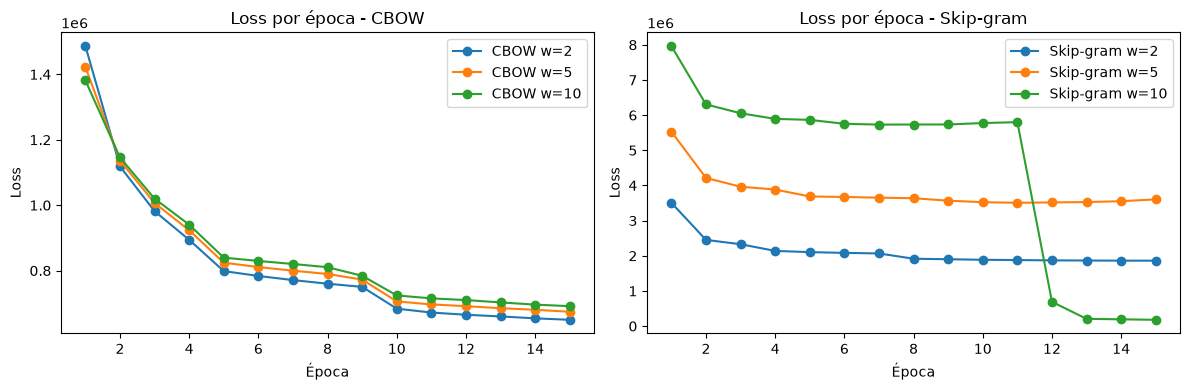

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, l in losses.items():
    ax = axes[0] if name.startswith("CBOW") else axes[1]
    ax.plot(range(1, len(l) + 1), l, marker="o", label=name)
for ax, title in zip(axes, ["CBOW", "Skip-gram"]):
    ax.set(title=f"Loss por época - {title}", xlabel="Época", ylabel="Loss")
    ax.legend()
plt.tight_layout()
plt.show()

En **CBOW** la loss baja de forma sostenida y se aplana hacia la época 15, así que 15 épocas alcanzan.

En **Skip-gram** hay que leer la curva con cuidado. La loss baja en las primeras épocas y después queda prácticamente plana. Con ventana 10, en la época 12 cae de golpe a casi 0, pero eso **no** es una mejora del modelo: es un problema conocido de cómo Gensim calcula la loss. Gensim la acumula en un número `float32`, y cuando el acumulado llega a ~67 millones (≈ 2²⁶) la precisión ya no alcanza para sumarle los incrementos pequeños de cada palabra, así que el acumulado deja de crecer. Skip-gram hace una predicción por cada par palabra-contexto, así que con ventana 10 acumula loss mucho más rápido y llega a ese límite antes. Por eso:
- las losses de distintas configuraciones **no son comparables** entre sí (cada una resuelve una tarea de predicción de distinto tamaño);
- la loss de Gensim sirve como referencia de convergencia, pero **para elegir el modelo usamos métricas sobre los vectores** (sección 3.2).

#### 3.1 - Evaluación cualitativa: vecinos más cercanos

In [9]:
QUERY = ["prince_andrew", "war", "french", "mother", "love", "dinner", "horse"]

def neighbors_table(models, words, topn=6):
    return pd.DataFrame({
        name: [", ".join(w for w, _ in m.wv.most_similar(q, topn=topn)) for q in words]
        for name, m in models.items()
    }, index=words)

neighbors_table({k: models[k] for k in ["CBOW w=5", "Skip-gram w=2", "Skip-gram w=5", "Skip-gram w=10"]}, QUERY)

,CBOW w=5,Skip-gram w=2,Skip-gram w=5,Skip-gram w=10
prince_andrew,"rostov, pierre, prince_vasili, anatole, nicholas, berg","pierre, prince_vasili, reluctantly, princess_mary, irritably, berthier","prince_vasili, pierre, willarski, kaysarov, he, kochubey","bolkonski, he, him, princess_mary, ironic_smile, continuing"
war,"russian_army, campaign, victory, battle, action, army","campaign, public, defeat, negotiations, wars, treachery","bonaparte, acting, wars, frontiers, campaign, oldenburg","oldenburg, jena, england, recruiting, intrigues, prussia"
french,"russian, russians, troops, prisoners, napoleon, french_army","russian, austrian, cavalry, russians, fleches, uvarov","russian, uvarov, french_army, prisoners, guards, russians","russian, russians, austrians, murat, guards, pursuing"
mother,"brother, husband, daughter, father, sister, son","parents, father, sister, beautiful_helene, son, mistress","father, brother, sisters, sonya, sister, her","father, brother, her, sonya, nataly, husband"
love,"pity, friendship, happiness, loved, loving, sorrow","friendship, sufferings, loved, reproach, self_sacrifice, talks","friendship, envy, loved, romantic, hate, inspire","friendship, inspire, loves, loved, earthly, romantic"
dinner,"supper, evening, review, rostovs, pause, home","supper, evening, dined, karagins, nap, sleepless_night","supper, nap, soiree, returned_home, karagins, funeral","supper, nap, funeral, soiree, great_deal, dine"
horse,"whip, hat, cap, sword, saddle, cossack","whip, hat, bobtailed, chestnut, bay, rein","whip, bobtailed, rider, rein, chestnut, spurred","bedouin, rider, spurred, saddle, rein, reined"


- **`prince_andrew`**: gracias a `Phrases` ahora tiene un vector propio. Sus vecinos son otros personajes masculinos (`pierre`, `prince_vasili`, `bolkonski`, su apellido) y, en Skip-gram, adverbios de diálogo (`irritably`, `reluctantly`, `ironic_smile`). Esto refleja frases típicas como *"said Prince Andrew coldly"*: el modelo aprendió *cómo habla* el personaje.
- **CBOW** devuelve vecinos de la misma categoría en las palabras frecuentes: `mother → brother, husband, daughter, father, sister, son`, `war → russian_army, campaign, victory, battle`.
- **Skip-gram** devuelve vecinos más **específicos** y más palabras raras: `horse → bobtailed, chestnut, rein, spurred`, `dinner → nap, soiree, karagins` (los Karagin son una familia que da cenas en la novela), `french → uvarov, guards, pursuing`.
- **Ventana:** al pasar de 2 a 10, los vecinos de `war` en Skip-gram van de `campaign, defeat, negotiations` (sintácticamente intercambiables) a `oldenburg, jena, england, prussia, intrigues` (palabras que aparecen *en los mismos pasajes* sobre la política europea). Las ventanas grandes capturan relaciones más **temáticas**.

Mirando solo los vecinos tendríamos la intuición de que "CBOW agrupa palabras intercambiables y Skip-gram agrupa por tema". Abajo vemos que las métricas **no confirman del todo** esa intuición.

#### 3.2 - Evaluación cuantitativa

Mirar vecinos es subjetivo, así que además medimos los modelos contra tres benchmarks estándar que vienen incluidos en Gensim:

| Benchmark | Qué mide | Métrica |
|---|---|---|
| **WordSim-353** | *Relación* entre palabras según jueces humanos (`coffee–cup` puntúa alto aunque no sean lo mismo) | Correlación de Spearman entre la similitud coseno y el puntaje humano |
| **SimLex-999** | *Similitud* estricta: palabras intercambiables (`cup–mug` alto, `coffee–cup` bajo) | Correlación de Spearman |
| **Analogías de Google** (`questions-words.txt`) | `a : b :: c : ?` en dos grupos: **semánticas** (capitales, monedas, familia) y **sintácticas** (plurales, tiempos verbales, comparativos) | % de aciertos (top-1) |

**Atención:** estos benchmarks están pensados para vocabularios generales en inglés moderno. Nuestro vocabulario tiene ~6.500 tokens de una novela del siglo XIX, así que **solo se puede evaluar una parte** de cada benchmark (lo indicamos en la columna de cobertura). Con ~100 pares evaluables, diferencias de 2 o 3 centésimas en la correlación no son significativas: usamos las métricas para ver **tendencias**, no para elegir por el tercer decimal.

In [10]:
WS, SL, AN = datapath("wordsim353.tsv"), datapath("simlex999.txt"), datapath("questions-words.txt")

def evaluate(wv):
    ws = wv.evaluate_word_pairs(WS)
    sl = wv.evaluate_word_pairs(SL)
    _, sections = wv.evaluate_word_analogies(AN)
    def acc(secs):
        ok = sum(len(s["correct"]) for s in secs)
        n = ok + sum(len(s["incorrect"]) for s in secs)
        return ok / n, n
    sem = acc([s for s in sections if not s["section"].startswith("gram") and s["section"] != "Total accuracy"])
    syn = acc([s for s in sections if s["section"].startswith("gram")])
    return {
        "WordSim ρ": ws[1].statistic, "WordSim cobertura %": 100 - ws[2],
        "SimLex ρ": sl[1].statistic, "SimLex cobertura %": 100 - sl[2],
        "Analogías sem. %": 100 * sem[0], "n sem.": sem[1],
        "Analogías sint. %": 100 * syn[0], "n sint.": syn[1],
    }

metrics = pd.DataFrame({name: evaluate(m.wv) for name, m in models.items()}).T
metrics.style.format("{:.3f}", subset=["WordSim ρ", "SimLex ρ"]).format(
    "{:.0f}", subset=["WordSim cobertura %", "SimLex cobertura %", "n sem.", "n sint."]).format(
    "{:.1f}", subset=["Analogías sem. %", "Analogías sint. %"])

,WordSim ρ,WordSim cobertura %,SimLex ρ,SimLex cobertura %,Analogías sem. %,n sem.,Analogías sint. %,n sint.
CBOW w=2,0.293,27,0.072,45,18.0,194,8.0,2599
CBOW w=5,0.388,27,0.072,45,12.4,194,9.7,2599
CBOW w=10,0.315,27,0.065,45,9.3,194,11.0,2599
Skip-gram w=2,0.272,27,0.125,45,13.9,194,6.2,2599
Skip-gram w=5,0.330,27,0.157,45,12.4,194,6.1,2599
Skip-gram w=10,0.370,27,0.148,45,10.8,194,6.1,2599


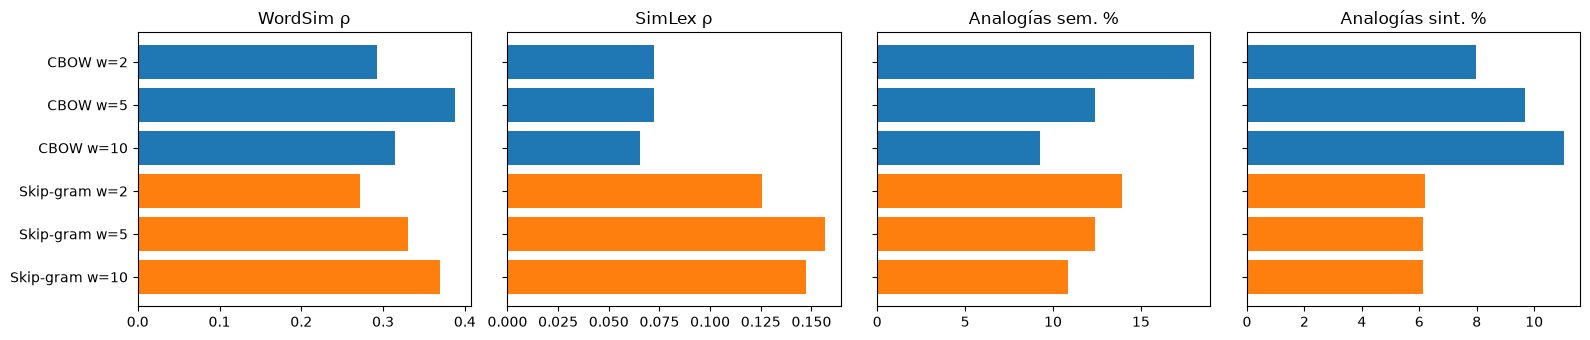

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["WordSim ρ", "SimLex ρ", "Analogías sem. %", "Analogías sint. %"]):
    colors = ["tab:blue" if n.startswith("CBOW") else "tab:orange" for n in metrics.index]
    ax.barh(metrics.index, metrics[col], color=colors)
    ax.set_title(col)
    ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
plt.tight_layout()
plt.show()

**Interpretación**

- **Cobertura:** solo el 27% de los pares de WordSim (~96 pares) y el 45% de SimLex (~450 pares) tienen sus dos palabras en nuestro vocabulario. Las analogías evaluables son 194 semánticas y 2.599 sintácticas. **SimLex es la métrica más confiable** de las cuatro, por tener más pares. Con ~96 pares, la correlación de WordSim puede variar ±0,1 solo por azar.
- **SimLex (similitud estricta): Skip-gram duplica a CBOW** con las tres ventanas (0,13–0,16 contra 0,07). Como la diferencia es sistemática, no es ruido. Esto **contradice** la intuición que sacamos de los vecinos (que CBOW captaba mejor las palabras intercambiables): en las palabras frecuentes CBOW parece ordenado, pero al promediar el contexto representa peor el conjunto completo de palabras, incluidas las menos frecuentes que aparecen en SimLex. Es una buena muestra de por qué conviene medir y no solo mirar ejemplos.
- **WordSim (relación temática):** el mejor es CBOW w=5 (0,39), seguido de Skip-gram w=10 (0,37). Con la cobertura que tenemos, las diferencias entre configuraciones no son concluyentes.
- **Analogías:** son bajas en todos los modelos (6–18%). Las **sintácticas** (plurales, tiempos verbales) favorecen a CBOW (8–11% contra ~6%). En las **semánticas** el mejor es CBOW w=2 (18%), pero son solo 194 analogías, en su mayoría capitales y monedas del mundo que casi no aparecen en la novela: 18% contra 12% son 35 contra 24 aciertos, así que no alcanza para elegir con confianza.
- **Dimensiones:** ningún modelo domina en todas las métricas.

**Modelo elegido: Skip-gram con ventana 5.** Es el mejor en la métrica más confiable (SimLex, 0,157), empata en analogías semánticas con CBOW w=5 (12,4%) y da los vecinos más ricos para palabras poco frecuentes (personajes, lugares, vocabulario militar), que son las que nos interesan para el análisis. Lo que se pierde frente a CBOW es rendimiento en analogías sintácticas, un aspecto que no es el foco del desafío (y que, como vemos en 3.4, resuelve mucho mejor FastText).

#### 3.3 - ¿Cambia algo aumentar la dimensión de los vectores?

Probamos el modelo elegido con `vector_size=300` (el valor usado en el notebook de clase).

In [12]:
FINAL = "Skip-gram w=5"
m300, _ = train_w2v(sg=1, window=5, vector_size=300)
pd.DataFrame({f"{FINAL} d=100": evaluate(models[FINAL].wv),
              f"{FINAL} d=300": evaluate(m300.wv)}).T.round(3)

,WordSim ρ,WordSim cobertura %,SimLex ρ,SimLex cobertura %,Analogías sem. %,n sem.,Analogías sint. %,n sint.
Skip-gram w=5 d=100,0.330,27.195,0.157,45.045,12.371,194.0,6.118,2599.0
Skip-gram w=5 d=300,0.309,27.195,0.176,45.045,8.763,194.0,4.309,2599.0


In [13]:
neighbors_table({f"{FINAL} d=100": models[FINAL], f"{FINAL} d=300": m300}, QUERY)

,Skip-gram w=5 d=100,Skip-gram w=5 d=300
prince_andrew,"prince_vasili, pierre, willarski, kaysarov, he, kochubey","prince_vasili, kaysarov, irritably, briefly, affectionately, pelageya"
war,"bonaparte, acting, wars, frontiers, campaign, oldenburg","frontiers, wars, oldenburg, acting, duke, discussion"
french,"russian, uvarov, french_army, prisoners, guards, russians","russian, uvarov, austrian, french_army, russians, austrians"
mother,"father, brother, sisters, sonya, sister, her","brother, sisters, parents, youngest, sister, old_countess"
love,"friendship, envy, loved, romantic, hate, inspire","friendship, hate, envy, madly, inspire, romantic"
dinner,"supper, nap, soiree, returned_home, karagins, funeral","supper, nap, karagins, soiree, returned_home, funeral"
horse,"whip, bobtailed, rider, rein, chestnut, spurred","bobtailed, whip, chestnut, spurred, rein, rider"


Con 300 dimensiones SimLex mejora apenas (0,157 → 0,176), pero empeoran WordSim y las dos clases de analogías, y los vecinos cambian poco (la mayoría se repiten con otro orden). Con ~6.800 tokens de vocabulario y ~560 mil tokens de texto no hay información suficiente para estimar bien 300 parámetros por palabra. El modelo tarda casi el triple en entrenar sin una mejora clara, así que **nos quedamos con 100 dimensiones**.

#### 3.4 - Comparación con FastText

FastText (visto en la clase 2) extiende Skip-gram/CBOW representando cada palabra como la suma de los vectores de sus **n-gramas de caracteres** (acá entre 3 y 6 caracteres). Esto tiene dos consecuencias que queremos verificar:
1. Las palabras que comparten raíz o terminación (`soldier/soldiers`, `cannon/cannonade`) comparten parámetros, así que deberían mejorar las **analogías sintácticas** (plurales, tiempos verbales).
2. Puede generar vectores para palabras **fuera del vocabulario** (OOV), cosa que Word2Vec no puede hacer.

Lo entrenamos con la misma configuración que el modelo Word2Vec elegido.

In [14]:
ft_model = FastText(sentence_tokens, vector_size=100, window=5, min_count=5, sg=1,
                    negative=10, epochs=15, min_n=3, max_n=6, workers=1, seed=SEED)

pd.DataFrame({f"Word2Vec {FINAL}": evaluate(models[FINAL].wv),
              f"FastText {FINAL}": evaluate(ft_model.wv)}).T.round(3)

,WordSim ρ,WordSim cobertura %,SimLex ρ,SimLex cobertura %,Analogías sem. %,n sem.,Analogías sint. %,n sint.
Word2Vec Skip-gram w=5,0.330,27.195,0.157,45.045,12.371,194.0,6.118,2599.0
FastText Skip-gram w=5,0.383,27.195,0.169,45.045,11.340,194.0,56.560,2599.0


In [15]:
neighbors_table({f"Word2Vec {FINAL}": models[FINAL], f"FastText {FINAL}": ft_model},
                ["natasha", "soldier", "cannon", "love", "moscow"])

,Word2Vec Skip-gram w=5,FastText Skip-gram w=5
natasha,"she, her, sonya, countess, princess_mary, countess_mary","malasha, masha, sonya, natalie, countess_mary, she"
soldier,"frenchman, accountant, gunner, sergeant, sentinel, grenadier","young_soldier, grenadier, soldiers, sergeant, infantry_officer, gunner"
cannon,"shots, musketry, captured, deafening, junot, trampling","cannonade, cannon_ball, cannon_balls, musketry, musket, wagon"
love,"friendship, envy, loved, romantic, hate, inspire","lover, loves, loved, friendship, grieve, lovely"
moscow,"town, inhabitants, smolensk, krems, villages, city","near_moscow, moscou, abandon_moscow, moscovites, smolensk, krems"


In [16]:
# Palabras que NO están en el vocabulario (no aparecen en el libro, o aparecen menos de 5 veces)
OOV = ["napoleonic", "cannonballs", "natashka", "battlefields"]
for w in OOV:
    in_w2v = w in models[FINAL].wv.key_to_index
    neighbors = ", ".join(x for x, _ in ft_model.wv.most_similar(w, topn=6))
    print(f"{w:13s} ¿en vocabulario Word2Vec? {str(in_w2v):5s} -> FastText: {neighbors}")

napoleonic    ¿en vocabulario Word2Vec? True  -> FastText: napoleon, republican, defeat, administrative, england, strategic
cannonballs   ¿en vocabulario Word2Vec? False -> FastText: cannon_balls, cannon_ball, cannonade, cannon, shells, projectiles
natashka      ¿en vocabulario Word2Vec? False -> FastText: natasha, malasha, natalie, masha, nataly, ivanushka
battlefields  ¿en vocabulario Word2Vec? False -> FastText: battlefield, battles, ryefield, batteries, pratzen_heights, field


**Interpretación**

- **Analogías sintácticas: de 6% a 57%.** Es la diferencia más grande del notebook y confirma la hipótesis: las analogías como `walk : walking :: swim : swimming` o `soldier : soldiers :: cannon : cannons` se resuelven casi solas cuando las palabras comparten n-gramas de caracteres. Las métricas semánticas (WordSim, SimLex, analogías semánticas) quedan en un nivel parecido al de Word2Vec.
- **Palabras fuera del vocabulario:** Word2Vec no puede representar `cannonballs`, `natashka` (diminutivo de Natasha) ni `battlefields`. FastText les arma un vector a partir de sus n-gramas y los vecinos tienen sentido: `cannonballs → cannon_balls, cannonade, shells, projectiles`, `natashka → natasha, natalie, nataly`. (`napoleonic` resultó estar en el vocabulario: aparece al menos 5 veces en los ensayos históricos.)
- **Contrapartida: sesgo hacia la forma de la palabra.** Los vecinos de FastText dependen mucho de la escritura: `natasha → malasha, masha` (son otros personajes y comparten `-asha`, pero no tienen nada que ver con Natasha), `love → lover, loves, lovely`, `battlefields → ryefield`. Word2Vec da vecinos más **semánticos** (`natasha → she, her, sonya, countess`).

**Decisión:** para el resto del análisis (similitudes y agrupamiento temático) seguimos con **Word2Vec**, porque queremos que la cercanía refleje significado y no ortografía. Si la tarea fuese, por ejemplo, etiquetado morfosintáctico o trabajar con texto con errores de tipeo y palabras nuevas, FastText sería claramente la mejor opción.

### 4 - Ensayar: términos más y menos similares

Usamos el modelo Word2Vec elegido. Mostramos su loss por época.

In [17]:
w2v_model = models[FINAL]
for epoch, loss in enumerate(losses[FINAL]):
    print(f"Loss after epoch {epoch}: {loss:,.0f}")
print("Cantidad de docs en el corpus:", w2v_model.corpus_count)
print("Cantidad de words distintas en el corpus:", len(w2v_model.wv.index_to_key))

Loss after epoch 0: 5,529,330
Loss after epoch 1: 4,215,140
Loss after epoch 2: 3,963,612
Loss after epoch 3: 3,884,748
Loss after epoch 4: 3,686,816
Loss after epoch 5: 3,672,700
Loss after epoch 6: 3,653,260
Loss after epoch 7: 3,636,972
Loss after epoch 8: 3,567,714
Loss after epoch 9: 3,524,236
Loss after epoch 10: 3,507,920
Loss after epoch 11: 3,517,012
Loss after epoch 12: 3,528,384
Loss after epoch 13: 3,552,344
Loss after epoch 14: 3,604,020
Cantidad de docs en el corpus: 30811
Cantidad de words distintas en el corpus: 6821


In [18]:
def most_and_least(word, topn=8):
    most = w2v_model.wv.most_similar(positive=[word], topn=topn)
    least = w2v_model.wv.most_similar(negative=[word], topn=topn)
    return pd.DataFrame({
        f"más similares a '{word}'": [f"{w} ({s:.2f})" for w, s in most],
        f"menos similares a '{word}'": [f"{w} ({s:.2f})" for w, s in least],
    })

TERMS = ["prince_andrew", "napoleon", "natasha", "cannon", "love", "moscow", "god"]
for t in TERMS:
    display(most_and_least(t))

,más similares a 'prince_andrew',menos similares a 'prince_andrew'
0,prince_vasili (0.62),hungry (0.01)
1,pierre (0.61),forces (-0.01)
2,willarski (0.61),virtue (-0.01)
3,kaysarov (0.59),us (-0.02)
4,he (0.58),unknown (-0.02)
5,kochubey (0.57),bodies (-0.03)
6,coldly (0.57),stone (-0.03)
7,affectionately (0.57),bees (-0.03)


,más similares a 'napoleon',menos similares a 'napoleon'
0,alexander (0.63),answered (0.03)
1,kutuzov (0.61),stood (0.02)
2,thiers (0.60),house (0.01)
3,bagration (0.60),kept (0.01)
4,davout (0.59),carriage (0.01)
5,duke (0.59),clean (0.01)
6,murat (0.58),exclaimed (0.01)
7,thirdly (0.58),open (0.01)


,más similares a 'natasha',menos similares a 'natasha'
0,she (0.68),divisions (0.07)
1,her (0.67),stationed (0.03)
2,sonya (0.64),standards (0.03)
3,countess (0.63),campan (0.02)
4,princess_mary (0.62),formed (0.01)
5,countess_mary (0.62),escort (0.01)
6,marya_dmitrievna (0.62),superior (0.01)
7,mademoiselle_bourienne (0.61),empire (0.01)


,más similares a 'cannon',menos similares a 'cannon'
0,shots (0.78),intimate (0.06)
1,musketry (0.74),friend (0.06)
2,captured (0.73),relations (0.04)
3,deafening (0.73),health (0.03)
4,junot (0.71),parents (0.03)
5,trampling (0.71),boris (0.02)
6,fired (0.71),berg (0.02)
7,campan (0.71),role (0.02)


,más similares a 'love',menos similares a 'love'
0,friendship (0.71),spread (0.04)
1,envy (0.65),rostopchin (0.02)
2,loved (0.63),stood (0.02)
3,romantic (0.62),suite (0.01)
4,hate (0.61),galloped (0.01)
5,inspire (0.60),sentinel (0.01)
6,harmony (0.60),steep (0.01)
7,repulsion (0.59),appeared (0.01)


,más similares a 'moscow',menos similares a 'moscow'
0,town (0.60),expression (-0.00)
1,inhabitants (0.60),question (-0.01)
2,smolensk (0.58),something (-0.01)
3,krems (0.58),elderly (-0.01)
4,villages (0.58),most (-0.01)
5,city (0.57),drawing (-0.01)
6,bogucharovo (0.57),quivered (-0.02)
7,voronezh (0.55),made (-0.02)


,más similares a 'god',menos similares a 'god'
0,heaven (0.71),became (0.06)
1,faith (0.70),amid (0.05)
2,o_lord (0.69),very (0.04)
3,almighty (0.68),approaching (0.04)
4,thy (0.68),longer (0.04)
5,lord (0.68),formed (0.04)
6,christ (0.68),begun (0.03)
7,grant (0.67),stood (0.03)


**Interpretación**

- **`prince_andrew`**: los vecinos son otros personajes masculinos de la aristocracia (`pierre`, `prince_vasili`, Willarski, Kochubey, Kaysarov) y adverbios de diálogo (`coldly`, `affectionately`). Esto refleja que en la novela casi siempre aparece en frases como *"said Prince Andrew coldly"*.
- **`napoleon`**: otros emperadores y generales (Alexander, Kutuzov, Bagration, los mariscales Davout y Murat) y el historiador *Thiers*, al que Tolstói discute en los capítulos ensayísticos. El modelo aprendió que Napoleón aparece en el mismo tipo de contexto que los demás líderes militares.
- **`natasha`**: pronombres femeninos (`she`, `her`) y **todos los demás personajes femeninos**: Sonya, la condesa, `princess_mary`, `countess_mary`, `marya_dmitrievna`, `mademoiselle_bourienne`. Gracias a `Phrases`, ahora varios de esos personajes de nombre compuesto tienen un vector propio. El embedding capturó claramente el **género** del personaje.
- **`cannon`**: el vocabulario sensorial de la batalla (`shots`, `musketry`, `deafening`, `fired`, `trampling`). Aparecen también algunos nombres propios (Junot, Campan) que comparten una o dos escenas: en un corpus chico, una palabra poco frecuente puede terminar cerca de otra por una sola coincidencia de contexto.
- **`love`**: otros sentimientos (`friendship`, `envy`, `harmony`, `romantic`) y también sus **opuestos** `hate` y `repulsion`. Los antónimos comparten contextos (*"I love/hate him"*), así que Word2Vec los ubica cerca. Es una limitación conocida de los embeddings distribucionales y una de las razones por las que el puntaje en SimLex es bajo.
- **`moscow`**: otras ciudades y lugares de la novela (`smolensk`, `krems`, `voronezh`, `bogucharovo`, la finca de los Bolkonski) y palabras como `town`, `inhabitants` y `villages`.
- **`god`**: vocabulario religioso y de oración (`heaven`, `faith`, `o_lord`, `almighty`, `thy`, `christ`, `grant` por *"God grant..."*). `o_lord` es otra frase detectada por `Phrases`.

**Menos similares:** las similitudes de estas palabras son prácticamente **0** (vectores casi ortogonales), no negativas. Es decir, no son "opuestos" sino palabras **no relacionadas**, de un mundo temático que nunca se cruza con la consulta. Para `cannon` aparece el mundo social y familiar (`intimate`, `friend`, `relations`, `parents`, `health`), y para `natasha` el mundo militar (`divisions`, `stationed`, `standards`, `escort`). Para `love` aparecen palabras de las marchas militares (`galloped`, `sentinel`, `suite`) y para `napoleon` las de las escenas domésticas (`house`, `carriage`, `exclaimed`). La estructura de la novela, que alterna escenas de *guerra* y de *paz*, aparece en el espacio de embeddings: lo más alejado de cada mundo es el otro.

#### Analogías

Con aritmética de vectores (`b - a + c`) probamos algunas analogías propias del corpus.

In [19]:
ANALOGIES = [  # (a, b, c): a es a b como c es a ?
    ("russia", "moscow", "france"),
    ("russian", "russia", "french"),
    ("father", "son", "mother"),
    ("he", "his", "she"),
    ("prince", "princess", "count"),
]
rows = []
for a, b, c in ANALOGIES:
    row = {"analogía": f"{b} - {a} + {c}"}
    for name in ["CBOW w=5", FINAL]:
        res = models[name].wv.most_similar(positive=[b, c], negative=[a], topn=4)
        row[name] = ", ".join(w for w, _ in res)
    rows.append(row)
pd.DataFrame(rows).set_index("analogía")

,CBOW w=5,Skip-gram w=5
analogía,,
moscow - russia + france,"days, household, fortnight, weeks","rhine, italy, eighty_thousand, year"
russia - russian + french,"army, russian_army, war, enemy","russian_army, french_army, france, ulm"
son - father + mother,"daughter, husband, wife, friend","youngest, daughters, countess, forgiveness"
his - he + she,"her, stooped, tears, slender","her, meekly, natasha, tenderly"
princess - prince + count,"countess, sonya, princess_mary, natasha","countess, young_lady, startled, anna_mikhaylovna"


- `his - he + she → her` (género gramatical) y `princess - prince + count → countess` (títulos nobiliarios) **funcionan en los dos modelos**. Esta última es una analogía propia del corpus: en la novela abundan los títulos.
- `son - father + mother → daughter` funciona en CBOW. En Skip-gram aparecen `youngest, daughters, countess`, que siguen en el campo correcto pero son menos precisos.
- Las analogías **geográficas** casi no funcionan. Skip-gram al menos devuelve palabras del campo correcto (`moscow - russia + france → rhine, italy`; `russia - russian + french → russian_army, french_army, france`, con `france` en tercer lugar), mientras que CBOW devuelve palabras sin relación (`days, household`). La novela casi no tiene frases del estilo "París es la capital de Francia": Word2Vec solo puede aprender las relaciones que el corpus contiene. Esto coincide con el bajo porcentaje de analogías semánticas de la sección 3.2.

### 5 - Visualización en 2D

**Decisiones para que el gráfico sea legible:**
- Filtramos **stopwords** y palabras de menos de 3 letras. Si no, las primeras posiciones por frecuencia se las llevan `the, and, of, to...`, que no aportan nada a la interpretación.
- Elegimos `MAX_WORDS = 250`: las 250 palabras de contenido más frecuentes. Con más de ~300 etiquetas el gráfico se vuelve ilegible. Con menos de ~150 se ven pocos grupos.
- Proyectamos con **t-SNE**, que preserva vecindades locales. Abajo verificamos con una métrica que conviene más que PCA.
- Coloreamos los puntos con **K-Means** aplicado sobre los vectores originales de 100 dimensiones (normalizados, para que equivalga a usar distancia coseno). Así el color refleja la estructura del espacio real y no un artefacto de la proyección. El número de grupos `k` lo elegimos con el coeficiente de **silhouette**.

In [20]:
MAX_WORDS = 250

content_words = [w for w in w2v_model.wv.index_to_key
                 if w not in ENGLISH_STOP_WORDS and len(w) >= 3 and "'" not in w][:MAX_WORDS]
X = w2v_model.wv[content_words]
X_norm = X / np.linalg.norm(X, axis=1, keepdims=True)
print("Frases incluidas en el gráfico:", [w for w in content_words if "_" in w])

Frases incluidas en el gráfico: ['prince_andrew', 'princess_mary', 'prince_vasili', 'old_man', 'drawing_room', 'anna_pavlovna']


#### 5.1 - ¿Cuántos grupos? Coeficiente de silhouette

El silhouette mide, para cada punto, cuánto más cerca está de su propio cluster que del cluster vecino. Va de -1 a 1: valores cercanos a 1 indican grupos compactos y bien separados, y valores cercanos a 0 indican grupos que se tocan.

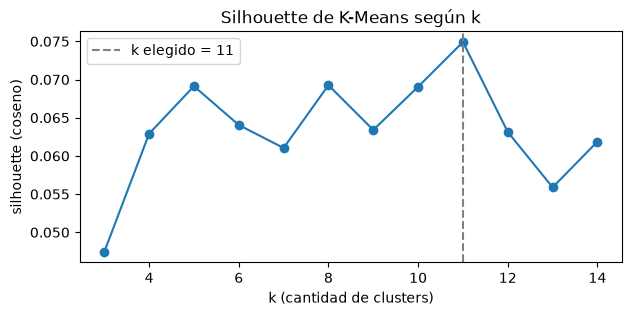

In [21]:
K_RANGE = range(3, 15)
sil = {k: silhouette_score(X_norm, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_norm),
                           metric="cosine") for k in K_RANGE}
N_CLUSTERS = max(sil, key=sil.get)

plt.figure(figsize=(7, 3))
plt.plot(list(sil), list(sil.values()), marker="o")
plt.axvline(N_CLUSTERS, color="gray", linestyle="--", label=f"k elegido = {N_CLUSTERS}")
plt.xlabel("k (cantidad de clusters)"); plt.ylabel("silhouette (coseno)")
plt.title("Silhouette de K-Means según k"); plt.legend()
plt.show()

clusters = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit_predict(X_norm)

Los valores de silhouette son **muy bajos para todo k** (entre 0,05 y 0,075) y la curva es casi plana: k = 5, 8, 10 y 11 dan valores prácticamente iguales. Esto es esperable en embeddings de palabras. El espacio es **continuo**: una palabra como `war` está a la vez cerca del vocabulario militar y del histórico-filosófico, y no hay fronteras nítidas entre grupos. Usamos el máximo (k=11), pero los clusters hay que leerlos como una **ayuda para interpretar** el gráfico y no como categorías naturales del lenguaje.

#### 5.2 - ¿t-SNE o PCA? ¿Es estable la proyección?

Para no interpretar artefactos de la proyección, medimos su calidad con **trustworthiness** (`sklearn.manifold.trustworthiness`). Esta métrica mide qué proporción de los 10 vecinos más cercanos de cada palabra *en el gráfico 2D* eran también vecinos cercanos en el espacio original de 100 dimensiones (1 = la proyección no inventa vecindades). Comparamos PCA con t-SNE para distintas `perplexity` (el tamaño efectivo del vecindario que t-SNE intenta preservar) y semillas.

In [22]:
projections = {"PCA": PCA(n_components=2, random_state=SEED).fit_transform(X_norm)}
for perp in (10, 20, 40):
    for seed in (0, SEED):
        projections[f"t-SNE perp={perp} seed={seed}"] = TSNE(
            n_components=2, perplexity=perp, metric="cosine", init="pca", random_state=seed).fit_transform(X)

trust = pd.Series({name: trustworthiness(X, emb, n_neighbors=10, metric="cosine")
                   for name, emb in projections.items()}, name="trustworthiness")
trust.to_frame().round(3)

,trustworthiness
PCA,0.718
t-SNE perp=10 seed=0,0.866
t-SNE perp=10 seed=42,0.866
t-SNE perp=20 seed=0,0.880
t-SNE perp=20 seed=42,0.880
t-SNE perp=40 seed=0,0.882
t-SNE perp=40 seed=42,0.882


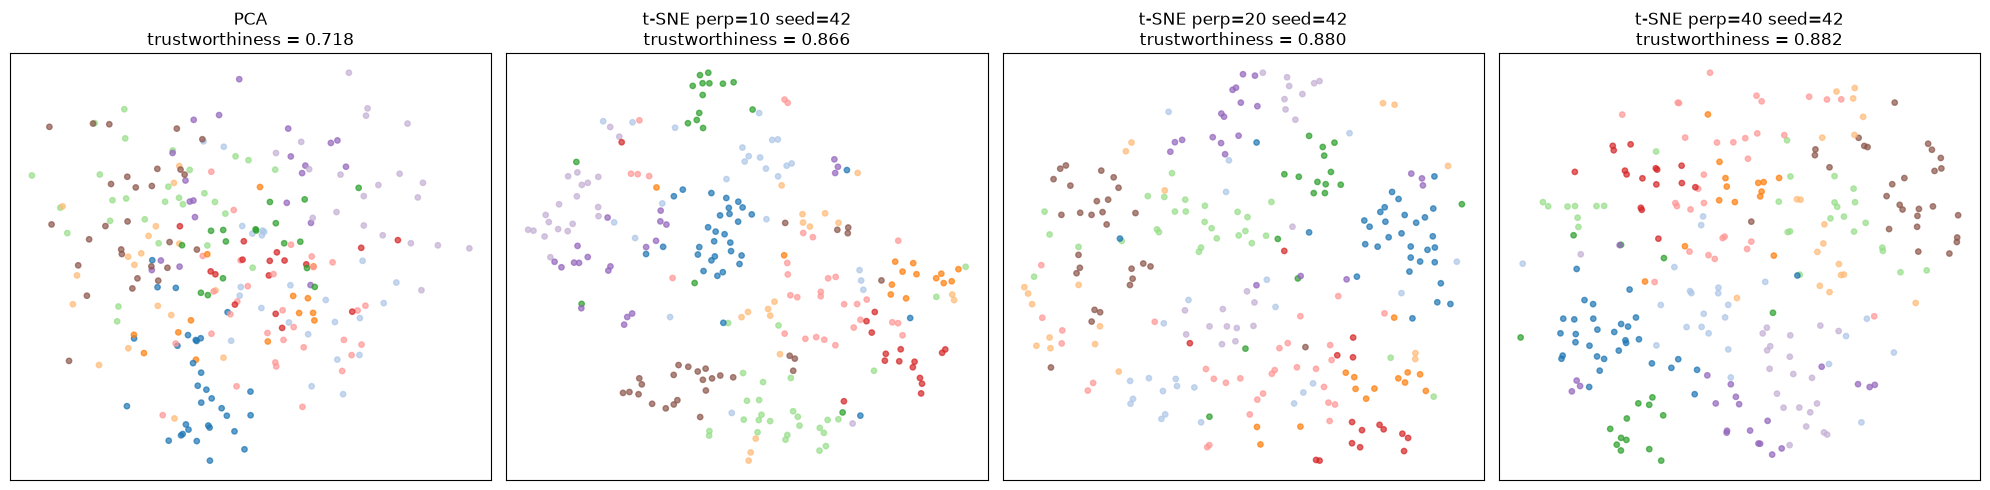

In [23]:
cmap = plt.get_cmap("tab20")

def plot_words(df, title, ax=None, fontsize=8, labels=True):
    ax = ax or plt.subplots(figsize=(16, 12))[1]
    ax.scatter(df.x, df.y, c=[cmap(c) for c in df.cluster], s=15, alpha=0.7)
    if labels:
        for _, r in df.iterrows():
            ax.annotate(r.word, (r.x, r.y), fontsize=fontsize, color=cmap(r.cluster),
                        xytext=(2, 2), textcoords="offset points")
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    return ax

def to_df(emb):
    return pd.DataFrame({"word": content_words, "x": emb[:, 0], "y": emb[:, 1], "cluster": clusters})

# Misma coloración (clusters en 100D) sobre distintas proyecciones
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, name in zip(axes, ["PCA", "t-SNE perp=10 seed=42", "t-SNE perp=20 seed=42", "t-SNE perp=40 seed=42"]):
    plot_words(to_df(projections[name]), f"{name}\ntrustworthiness = {trust[name]:.3f}", ax=ax, labels=False)
plt.tight_layout()
plt.show()

- **t-SNE preserva mucho mejor las vecindades que PCA** (trustworthiness ~0,87–0,88 contra 0,72). En el gráfico de PCA los colores están mezclados: PCA preserva la varianza global, pero con 100 dimensiones y estructura no lineal, 2 componentes no alcanzan para separar los grupos.
- **La semilla no cambia el resultado** (mismos valores con seed 0 y 42), porque inicializamos t-SNE con PCA (`init="pca"`), lo que lo hace prácticamente determinista.
- **La perplexity cambia la forma del gráfico, pero no los grupos.** Con 10, 20 o 40, los mismos colores (que vienen de clusters calculados en 100 dimensiones, *no* en 2D) siguen formando regiones compactas: por ejemplo, los personajes y la familia (azul oscuro), el tiempo y los lugares (verde) y los verbos de voluntad (rojo). Como esos grupos aparecen con cualquier configuración, no son artefactos de la proyección. Usamos **perplexity 20**: casi la misma trustworthiness que 40 y grupos más compactos y legibles.

#### 5.3 - Gráfico final

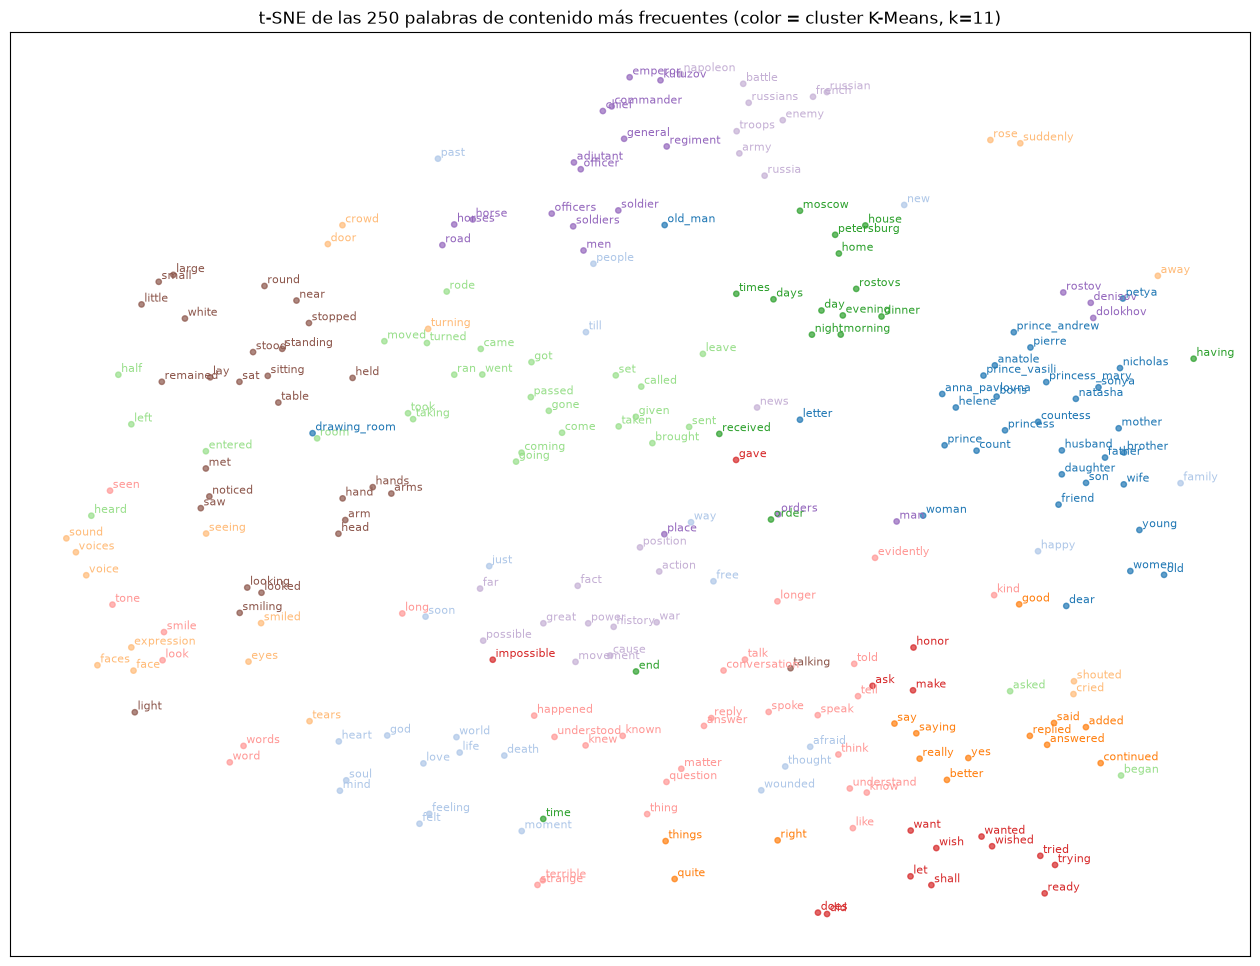

In [24]:
viz = to_df(projections["t-SNE perp=20 seed=42"])
plot_words(viz, f"t-SNE de las {MAX_WORDS} palabras de contenido más frecuentes "
                f"(color = cluster K-Means, k={N_CLUSTERS})")
plt.show()

In [25]:
# Palabras de cada cluster, para interpretar los grupos
for c, words in viz.groupby("cluster").word:
    print(f"Cluster {c} ({len(words)} palabras): {', '.join(words)}\n")

Cluster 0 (32 palabras): pierre, natasha, prince_andrew, nicholas, princess_mary, count, father, sonya, prince, old, countess, princess, boris, wife, son, mother, petya, dear, letter, prince_vasili, young, anatole, friend, old_man, brother, woman, helene, husband, drawing_room, daughter, anna_pavlovna, women

Cluster 1 (24 palabras): thought, felt, life, just, people, way, love, moment, feeling, new, soon, mind, god, happy, death, wounded, heart, till, past, soul, free, world, afraid, family

Cluster 2 (14 palabras): said, say, right, good, quite, yes, replied, things, saying, continued, really, added, better, answered

Cluster 3 (18 palabras): face, eyes, suddenly, away, voice, door, expression, crowd, shouted, rose, cried, seeing, turning, tears, sound, faces, voices, smiled

Cluster 4 (17 palabras): time, moscow, day, having, house, order, petersburg, night, evening, morning, received, end, days, dinner, home, rostovs, times

Cluster 5 (28 palabras): went, came, began, come, left, r

Versión **interactiva** (plotly, como en el notebook de clase): se puede hacer zoom y pasar el mouse por encima de los puntos para ver la palabra y su cluster.

In [26]:
fig = px.scatter(viz.assign(cluster=viz.cluster.astype(str)), x="x", y="y", text="word", color="cluster",
                 hover_name="word", title=f"t-SNE interactivo ({MAX_WORDS} palabras)",
                 width=1000, height=750, color_discrete_sequence=px.colors.qualitative.Dark24)
fig.update_traces(textposition="top center", textfont_size=9, marker_size=5)
fig.update_layout(xaxis_visible=False, yaxis_visible=False)
fig.show()

#### 5.4 - Zoom sobre grupos de palabras

Para cada grupo que identificamos tomamos un conjunto de palabras "semilla", buscamos dónde caen en la proyección y graficamos (zoom) la región que las rodea.

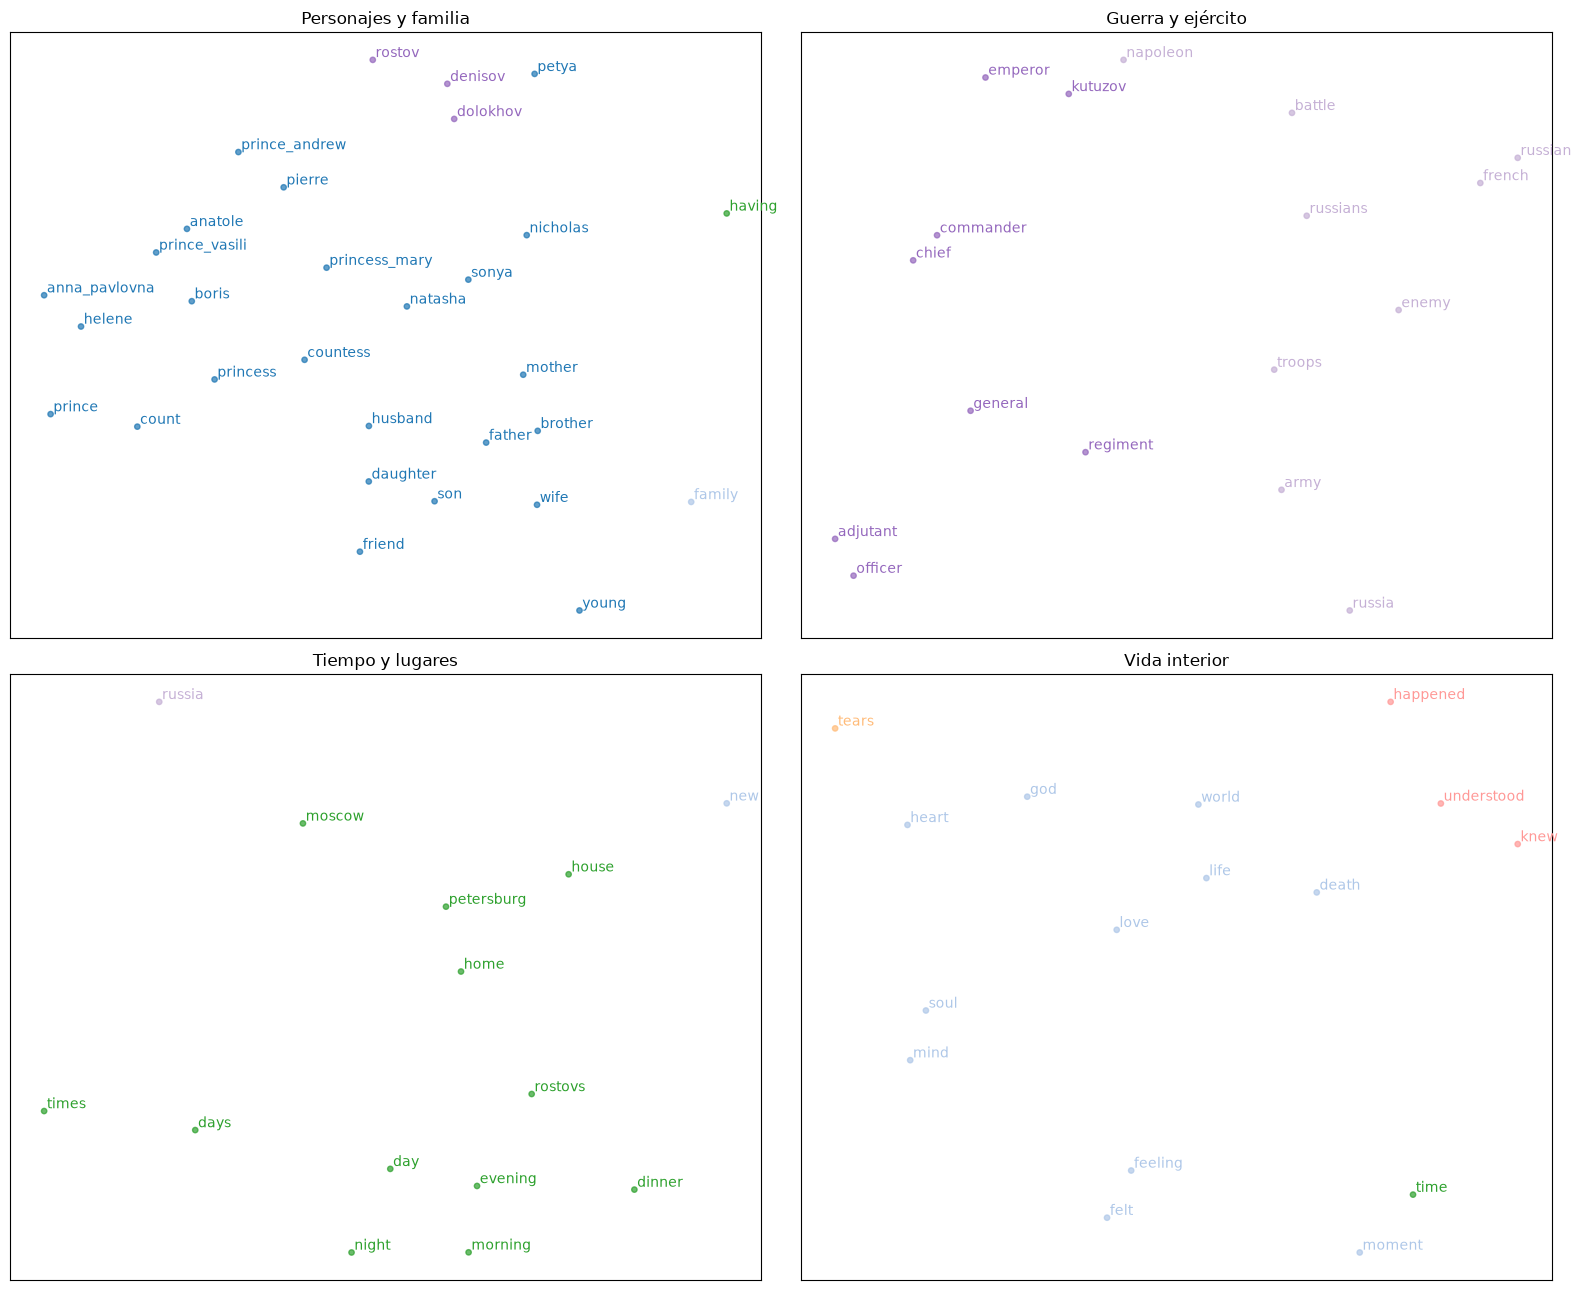

In [27]:
GROUPS = {
    "Personajes y familia": ["natasha", "sonya", "prince_andrew", "princess_mary", "mother", "father", "wife", "son"],
    "Guerra y ejército": ["emperor", "napoleon", "kutuzov", "commander", "general", "troops", "enemy", "army"],
    "Tiempo y lugares": ["morning", "evening", "night", "dinner", "moscow", "petersburg", "home", "house"],
    "Vida interior": ["heart", "soul", "mind", "feeling", "felt", "love", "life", "death", "god"],
}

def zoom(seeds, ax, title, margin=3):
    pts = viz[viz.word.isin(seeds)]
    x0, x1, y0, y1 = pts.x.min() - margin, pts.x.max() + margin, pts.y.min() - margin, pts.y.max() + margin
    region = viz[viz.x.between(x0, x1) & viz.y.between(y0, y1)]
    plot_words(region, title, ax=ax, fontsize=10)

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for ax, (title, seeds) in zip(axes.ravel(), GROUPS.items()):
    zoom([s for s in seeds if s in set(viz.word)], ax, title)
plt.tight_layout()
plt.show()

#### Interpretación de los grupos

Con k=11, K-Means (en 100 dimensiones) y t-SNE (en 2D) coinciden en regiones bien interpretables:

1. **Personajes y familia** (azul, derecha): los protagonistas (`natasha, sonya, pierre, prince_andrew, princess_mary, nicholas, helene, anatole, prince_vasili, anna_pavlovna`) junto con el parentesco (`mother, father, wife, husband, son, daughter, brother`), los títulos (`prince, princess, count, countess`) y el `drawing_room`, el salón donde transcurren las escenas de la alta sociedad. Gracias a `Phrases`, Prince Andrew y Princess Mary aparecen como puntos propios dentro de su familia.
2. **Los húsares, entre la familia y el ejército.** `rostov, denisov, dolokhov` (y `petya`, el hermano menor de Natasha que se une a la guerrilla) forman un subgrupo pegado a la familia en el gráfico. K-Means deja a Petya con la familia, pero asigna los otros tres al cluster **militar**. Es el grupo de oficiales de caballería que vive tanto las escenas familiares como las de batalla, y el modelo lo ubica justamente en la frontera. Además, Nicolás Rostov aparece como `nicholas` en la familia y como `rostov` entre los militares, porque Tolstói lo nombra distinto según la escena.
3. **Ejército** (violeta, arriba): la jerarquía militar (`emperor, kutuzov, commander, general, adjutant, officer, soldiers, regiment`) y lo que la acompaña en campaña (`horse, road, orders`).
4. **La guerra como proceso histórico** (lila, arriba y centro): `french, russian, napoleon, army, battle, enemy, troops`, mezclado con `history, power, cause, movement, action, fact`. Es uno de los hallazgos más interesantes: el modelo junta la guerra con el **vocabulario de los ensayos filosóficos de Tolstói** sobre las causas de la historia y el poder, porque en la novela esas reflexiones se hacen siempre a propósito de la campaña de 1812.
5. **Tiempo y lugares** (verde, centro): `morning, evening, night, day, dinner` junto a `moscow, petersburg, home, house, rostovs`. Son las palabras que *sitúan* una escena ("esa noche, en Moscú, en casa de los Rostov...").
6. **Vida interior** (celeste, abajo a la izquierda): `heart, soul, mind, feeling, felt, love, life, death, god, world, happy`. Son las reflexiones existenciales de Pierre y Andrew, y queda claramente separado del cluster histórico-filosófico. El modelo distingue la filosofía de la *historia* de la filosofía de la *vida personal*.
7. **Rostro, voz y sonido** (naranja claro, izquierda): `face, eyes, expression, smiled, tears, voice, voices, sound`. Tolstói describe constantemente las emociones a través del rostro y la voz de los personajes.
8. **Cuerpo y postura** (marrón, izquierda): `hand(s), arm(s), head, sat, stood, lay, sitting, standing, table`. Queda separado del rostro: el modelo distingue el cuerpo *que expresa* del cuerpo *que se ubica en la escena*.
9. **Verbos de movimiento y de dar/recibir** (verde claro, centro): `went, came, ran, rode, entered, moved, passed` y `sent, brought, given, taken`.
10. **Verbos de habla y conocimiento**: el cluster naranja (`said, replied, answered, added, continued`, las palabras que cierran un diálogo) y el rosa (`know, understand, think, tell, talk, question, conversation`).
11. **Voluntad** (rojo, abajo a la derecha): `want, wanted, wish, wished, tried, trying, let, shall, ready`. Es un grupo puramente **sintáctico**: son verbos que van seguidos de un infinitivo (*"he wanted to..."*).

**Conclusión de la visualización:** el mapa combina grupos **semánticos** (familia, guerra, lugares, vida interior) y **sintácticos** (verbos de habla, voluntad, movimiento). La parte superior concentra la *guerra* (ejército e historia), la derecha la *paz* (familia y salones), y el vocabulario narrativo (gestos, verbos) ocupa la parte inferior: la estructura temática de la novela se ve en el espacio de embeddings.

### 6 - Conclusiones

- **El corpus importa más que los hiperparámetros.** Con ~30 mil tokens (una banda o una poeta) los vecinos eran casi aleatorios. Con ~560 mil tokens de un libro, Word2Vec aprende relaciones reconocibles: personajes según género y familia, vocabulario militar, lugares, emociones e incluso la distinción entre los ensayos históricos y la vida interior de los personajes.
- **El preprocesamiento específico del corpus vale la pena.** Quitar acentos rescató los nombres rusos, y `Phrases` (filtrado para no unir stopwords) dio vectores propios a `prince_andrew`, `princess_mary` o `anna_pavlovna`. Además verificamos con métricas que aplicar `Phrases` sin filtrar empeoraba los resultados.
- **Medir corrige la intuición.** Mirando vecinos creíamos que CBOW captaba mejor las palabras intercambiables, pero SimLex mostró lo contrario: Skip-gram duplica a CBOW en todas las ventanas. Las métricas también tienen límites: la cobertura es baja (27–45%) y con ~100 pares las diferencias chicas no son significativas. Por eso combinamos métricas y análisis cualitativo para elegir **Skip-gram, ventana 5, 100 dimensiones**.
- **Más dimensiones no ayudan con poco texto:** pasar de 100 a 300 no mejoró de forma consistente y casi triplicó el tiempo de entrenamiento.
- **FastText vs Word2Vec es un trade-off:** FastText multiplica por 9 las analogías sintácticas y representa palabras que no vio (`cannonballs`, `natashka`), pero a costa de agrupar por ortografía (`natasha → malasha`). Para análisis semántico preferimos Word2Vec.
- **Los embeddings heredan las particularidades del corpus:** `love` queda cerca de `hate` (comparten contextos), las analogías geográficas fallan porque la novela no habla de capitales, y las palabras "menos similares" reflejan *distancia temática* (guerra vs paz) más que antónimos.
- **Visualizar con método:** t-SNE preserva vecindades mucho mejor que PCA (trustworthiness 0,88 vs 0,72), los grupos se mantienen al variar la perplexity y la semilla, y los clusters calculados en el espacio original (no en 2D) evitan interpretar artefactos de la proyección. El silhouette bajo nos recuerda que el espacio es continuo y que los grupos son una herramienta de lectura, no categorías absolutas.